# Modeling: E2, image size (Colab GPU)

**Question:** does a larger input image help the ball? At the default `imgsz=640` the 3024 px frame shrinks 4.7×, so the ball's median short side is about 8 px, around one cell of YOLO's finest grid (stride 8).

Runs, all with E1's settings except the image size:

| Run | imgsz | Ball size (median short side) | Why |
|---|---|---|---|
| `E2_yolo26s_640_v1b` | 640 | ~8 px | **Control:** E1 again, but on this GPU. Compared with the Mac's E1 seeds (`07` §1), it shows whether the GPU type changes the numbers. |
| `E2_yolo26s_960_v1b` | 960 | ~11 px | In between: is the gain gradual? |
| `E2_yolo26s_1280_v1b` | 1280 | ~15 px | Biggest size we can afford. Does not fit on the Mac (out of memory at 1280, see `02` §3). |

This notebook needs a **CUDA GPU** (Colab: *Runtime → Change runtime type → T4 GPU*). Runs are saved to Google Drive, so a disconnect loses nothing: re-run all cells and an unfinished run resumes.

> **GenAI:** written with Claude Code on 2026-11-11: code, hypothesis texts (from `modeling/README.md` §5–§6, the E1 curves and the error-analysis hypotheses in `03_error_analysis.ipynb` §7), and a check of the Ultralytics 8.4.192 source for mosaic and checkpoints. Details in [`modeling/README.md` §12](../modeling/README.md#12-genai-disclosure). What we checked or changed ourselves: _to fill in_.

## 0. Setup

On Colab: mount Drive, clone the repo, install the **same Ultralytics version as the Mac** (8.4.192, so the training code is identical), and build the dataset from the video with `data/prepare_dataset.py` (it prints `train: 48 images, val: 25 images`).

In [ ]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not Path("/content/computer-vision").exists():
        !git clone -q https://github.com/Patiukdanylo/computer-vision.git /content/computer-vision
    %cd /content/computer-vision
    !pip install -q "ultralytics==8.4.192"
    !python data/prepare_dataset.py

Mounted at /content/drive
/content/computer-vision
Wrote /content/computer-vision/data/cycle-ball-dataset
  train: 48 images, val: 25 images (val = frames 1-234)


In [ ]:
import os
os.environ["YOLO_VERBOSE"] = "False"   # before importing ultralytics: no per-epoch logs (the numbers are in each run's results.csv)

from pathlib import Path

import pandas as pd
import torch
import ultralytics
from IPython.display import Image, display
from ultralytics import YOLO

ROOT = Path("/content/computer-vision") if IN_COLAB else Path.cwd().parent
VERSION = "v1b"                               # dataset version, part of every run name
DATA = ROOT / "data/cycle-ball-dataset"
RUNS = Path("/content/drive/MyDrive/cycle-ball/runs/modeling") if IN_COLAB else ROOT / "runs/modeling"
MODEL = "yolo26s.pt"
ARCH = Path(MODEL).stem
DEVICE = 0 if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
BATCH = 16      # Ultralytics default. If 1280 runs out of GPU memory, use 8: gradients are accumulated to a nominal batch of 64 anyway (nbs)

assert DEVICE == 0, "E2 needs a CUDA GPU (Runtime > Change runtime type > T4 GPU); 1280 does not fit on the Mac"
print(torch.cuda.get_device_name(0))
n = {s: len(list((DATA / "images" / s).glob("*.jpg"))) for s in ("train", "val")}
assert n == {"train": 48, "val": 25}, f"expected dataset {VERSION} (48 train / 25 val), found {n}"
print("dataset", VERSION, n, "| ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device", DEVICE)

Tesla T4
dataset v1b {'train': 48, 'val': 25} | ultralytics 8.4.192 | torch 2.14.1+cu130 | device 0


### Helpers

- `train(name, **overrides)`: trains with E1's settings (defaults, `imgsz=640`, `seed=0`) plus the one factor we change. A finished run is skipped, so re-running the notebook only re-validates. A run that was cut off (crash, closed laptop, Colab disconnect) is resumed from `last.pt`: Ultralytics marks a finished checkpoint with `epoch = -1` (`strip_optimizer` in `utils/torch_utils.py`).
- `evaluate(label, best)`: validates `best.pt` on val and returns one row: ball AP50 and AP50-95, player and bike AP50-95, the **selection metric** (mean AP50-95 over ball, player and bike; `goal` is near-perfect and left out), the all-class mAP YOLO reports, the epoch `best.pt` came from, training time and inference ms per image. `save_json=True` writes `predictions.json` for the error analysis.
- `show(rows, ref, noise)`: the comparison table. `Δ selection` is the difference with the reference; `beyond noise` says whether it is larger than the spread between E1 seeds (07 §1).

In [ ]:
CLASSES = ("ball", "player", "bike")   # selection metric = mean AP50-95 over these; goal is near-perfect and left out
VAL = {}                               # label -> full val result, for cells that need more than the table


def train(name, model=MODEL, **overrides):
    """Train into RUNS/name and return its best.pt. A finished run is skipped, a run that was cut off is resumed."""
    last = RUNS / name / "weights/last.pt"
    if not last.exists():
        args = dict(data=str(DATA / "data.yaml"), imgsz=640, seed=0, device=DEVICE, project=str(RUNS), name=name, exist_ok=True)
        YOLO(model).train(**args | overrides)
    elif torch.load(last, map_location="cpu", weights_only=False)["epoch"] != -1:   # Ultralytics sets epoch to -1 when a run finishes
        YOLO(last).train(resume=True)
    return RUNS / name / "weights/best.pt"


def evaluate(label, best, imgsz=640, suffix="", **kw):
    """Validate best.pt on val and return one table row. Extra keyword arguments go to val (e.g. iou=0.5)."""
    run = best.parent.parent
    r = YOLO(best).val(data=str(DATA / "data.yaml"), imgsz=imgsz, device=DEVICE, project=str(RUNS),
                       name=f"{run.name}_val{suffix}", save_json=True, exist_ok=True, **kw)
    VAL[label] = r
    ap = {r.names[c]: (r.box.ap50[i], r.box.ap[i]) for i, c in enumerate(r.box.ap_class_index)}
    log = pd.read_csv(run / "results.csv")
    fitness = log["metrics/mAP50-95(B)"]           # what Ultralytics 8.4.192 uses to pick best.pt
    return {
        "run": label,
        "ball AP50": ap["ball"][0],
        "ball AP50-95": ap["ball"][1],
        "player AP50-95": ap["player"][1],
        "bike AP50-95": ap["bike"][1],
        "selection": sum(ap[c][1] for c in CLASSES) / len(CLASSES),
        "mAP50 all": r.box.map50,
        "mAP50-95 all": r.box.map,
        "best epoch": f"{int(log.epoch[fitness.idxmax()])} / {len(log)}",
        "train min": log.time.iloc[-1] / 60,
        "ms / img": r.speed["inference"],
    }


def show(rows, ref=None, noise=None):
    """Comparison table. With ref: the difference in the selection metric. With noise: whether it beats the seed spread."""
    df = pd.DataFrame(rows).set_index("run")
    if ref is not None:
        df.insert(df.columns.get_loc("selection") + 1, "Δ selection", df["selection"] - ref)
    if noise is not None:
        df.insert(df.columns.get_loc("Δ selection") + 1, "beyond noise", df["Δ selection"].abs() > noise)
    display(df.round(3))
    return df

## 1. E2: train at 640, 960 and 1280

**Hypothesis (written 11 Nov, before the run):**

- **Ball AP50-95 gains the most.** Error analysis hypothesis #2: ball AP50-95 is 0.226 against AP50 0.521, because at ~8 px a 2 px shift of the box costs a lot of IoU. At ~15 px the same shift costs much less.
- **Ball AP50 gains less.** Most missed balls are in the scrum, half hidden or blurred, and they are *not* smaller than the found ones (error analysis §3). A bigger image doesn't un-hide a ball.
- **Bike AP50-95 goes up.** The untrained model already improves from 640 to 1280 (bike AP50-95 0.510 → 0.624, E0 in `02`).
- **Player about the same.** Riders are large already.
- **Cost:** about (1280/640)² = 4× the pixels, so roughly 2–4× training time and ms per image.
- **Control:** the 640 run lands inside the Mac's E1 seed range (`07` §1). If it doesn't, the GPU is one more source of noise, and the 960 and 1280 rows are compared with this control, not with the Mac.

About 30–60 min in total on a T4 (estimate).

In [ ]:
rows = [evaluate(f"E2 @{s}", train(f"E2_{ARCH}_{s}_{VERSION}", imgsz=s, batch=BATCH), imgsz=s) for s in (640, 960, 1280)]
e2 = show(rows, ref=rows[0]["selection"])      # Δ = difference with the 640 control on the same GPU

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,
E2 @640,0.617,0.241,0.545,0.598,0.462,0.000,0.886,0.595,97 / 100,4.749,10.078
E2 @960,0.750,0.422,0.575,0.635,0.544,0.082,0.915,0.657,88 / 100,7.339,20.110
E2 @1280,0.578,0.410,0.585,0.559,0.518,0.057,0.862,0.638,90 / 100,9.669,17.984


## 1b. `yolo26m` at batch 16

On the Mac (`07` §6) `yolo26m` was the only run that beat E1 beyond noise (selection metric 0.503 against the E1 seed mean 0.468), but it had to run with `batch=8`, because 16 didn't fit in memory. Here it runs with `batch=16` like every other run, and is compared with the 640 control above, on the same GPU.

**Hypothesis:** the gain holds, mostly on the ball (Mac: ball AP50 0.651 against 0.52–0.57 for `yolo26s`). Batch size should not matter much: the optimizer steps are the same either way (nominal batch 64), only BatchNorm sees more images at once.

In [ ]:
m_row = evaluate("E6 yolo26m @640, batch 16", train(f"E6_yolo26m_640_{VERSION}", model="yolo26m.pt", batch=16))
show([rows[0], m_row], ref=rows[0]["selection"]);

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,
E2 @640,0.617,0.241,0.545,0.598,0.462,0.000,0.886,0.595,97 / 100,4.749,10.078
"E6 yolo26m @640, batch 16",0.342,0.186,0.576,0.552,0.438,-0.024,0.802,0.577,91 / 100,9.232,18.443


## 1c. E2 @960 with seeds 1 and 2

960 is the best size in §1 (one seed), so it is re-run with seeds 1 and 2, like E1 in `07` §1, and judged with the same noise yardstick: the E1 seed range, 0.024.

*Added after the run:* the seed runs were trained on 13 Nov from a cell that was not kept, so the training cell below has no output; the table under it does. The run names follow `07` §1 (`…_s1`, `…_s2`). If the folders on Drive are named differently, re-running trains them again (about 7 min each on a T4).

In [ ]:
rows += [evaluate(f"E2 @960 s{s}", train(f"E2_{ARCH}_960_{VERSION}_s{s}", imgsz=960, batch=BATCH, seed=s), imgsz=960)
         for s in (1, 2)]

In [9]:
e2s = show(rows, ref=rows[0]["selection"], noise=0.024)   # rows[0] = E2 @640 control
e2s.loc[["E2 @960", "E2 @960 s1", "E2 @960 s2"], "selection"].agg(["mean", "std", "min"])

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,beyond noise,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,,
E2 @640,0.617,0.241,0.545,0.598,0.462,0.000,False,0.886,0.595,97 / 100,4.749,10.078
E2 @960,0.750,0.422,0.575,0.635,0.544,0.082,True,0.915,0.657,88 / 100,7.339,20.110
E2 @1280,0.578,0.410,0.585,0.559,0.518,0.057,True,0.862,0.638,90 / 100,9.669,17.984
E2 @960 s1,0.718,0.421,0.517,0.616,0.518,0.057,True,0.903,0.637,92 / 100,7.351,10.411
E2 @960 s2,0.630,0.385,0.535,0.645,0.522,0.060,True,0.884,0.640,93 / 100,7.372,10.268


,selection
mean,0.527803
std,0.013938
min,0.518046


## 2. Training curves at 1280

Same reading as `02` §4: train and val losses should both fall; val falling while train keeps falling means the model still learns. The step in the last 10 epochs is mosaic switching off.

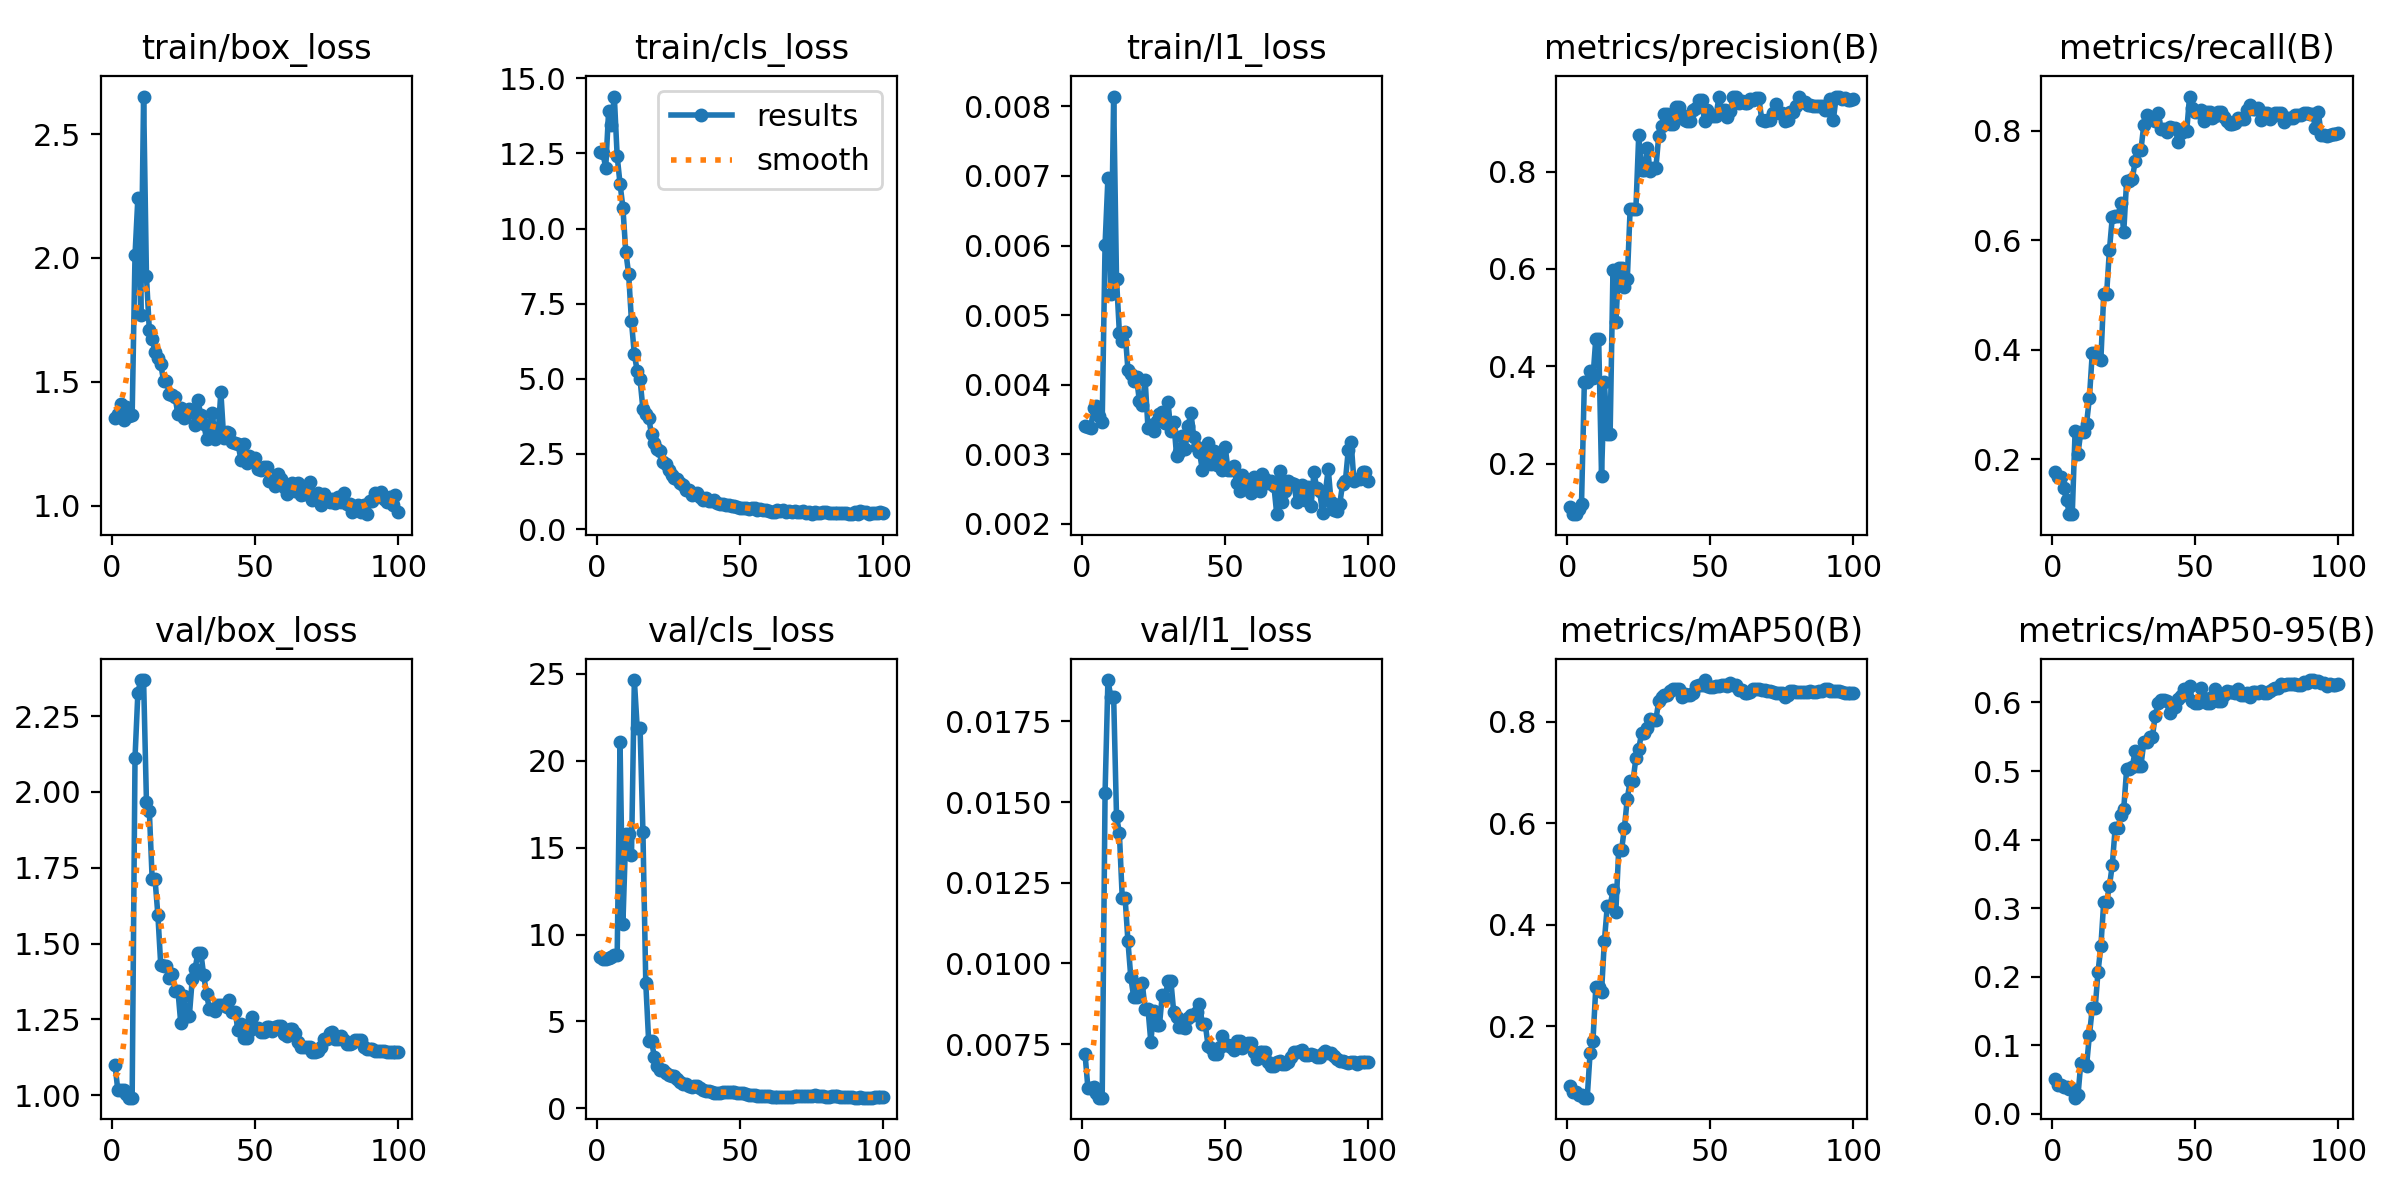

In [ ]:
display(Image(filename=str(RUNS / f"E2_{ARCH}_1280_{VERSION}/results.png"), width=900))

## 3. After the run

- The run folders are on Drive in `cycle-ball/runs/modeling/`. Download them into `runs/modeling/` on the Mac, so the error analysis (`03`, set `MODEL`) and the app can use them.
- `ms / img` here is a Colab GPU number, not the app's. The app reads precomputed detections (`models/detections.csv`), so speed only matters when a new clip is processed. Measure it on the Mac for the final model.
- Add the rows (E2 at three sizes, `yolo26m` at batch 16) to the mAP log in [`modeling/README.md` §9](../modeling/README.md#9-experiment-log-map-log).

## 4. Conclusions

Run on a Colab Tesla T4 on 13 Nov (Ultralytics 8.4.192, torch 2.14.1+cu130). "Selection" = mean AP50-95 over ball, player and bike; the noise yardstick is the E1 seed range, 0.024 (`07` §1).

**E2 hypotheses (§1)**

| Hypothesis | Verdict | Numbers (640 → 960 → 1280) |
|---|---|---|
| Control: 640 lands inside the Mac's E1 seed range | **Confirmed** | Selection 0.462; Mac seeds 0.455–0.479. The T4 adds no shift of its own, so T4 and Mac rows can be compared. |
| Ball AP50-95 gains the most | **Confirmed** | 0.241 → 0.422 → 0.410 (960 seeds 0.385–0.422). The largest gain of any class; at 960 player AP50-95 gains 0.03 and bike 0.04. |
| Ball AP50 gains less | **Partly** | 0.617 → 0.750 → 0.578. At 960 +0.13 (all three seeds above 0.617: 0.630–0.750), less than AP50-95 (+0.18) but not small, so 960 does find some balls that 640 misses. At 1280 it is below 640. Which balls: error analysis (`03`) on the 960 model. |
| Bike AP50-95 goes up | **Partly** | 0.598 → 0.635 → 0.559: up at 960 (seeds 0.616–0.645), down at 1280. |
| Player about the same | **Confirmed** | 0.545 → 0.575 → 0.585 (960 seeds 0.517–0.575). |
| Cost 2–4× | **Lower than expected** | Training 4.7 → 7.3 → 9.7 min (1.5× and 2.0×). `ms / img` on Colab is not reliable: 20.1 ms for 960 seed 0 but 10.4 and 10.3 ms for seeds 1 and 2, same model and size. Measure the champion on the Mac. |

**960 vs 1280.** 1280 (selection 0.518, one seed) sits at the bottom of the 960 seed range (0.518–0.544): no better than 960, for 1.3× the training time and 1.8× the pixels. The gain does not keep growing with size.

**Seeds at 960 (§1c).** 0.544, 0.518, 0.522 → **0.528 ± 0.014**, against E1 at 640 (Mac, 3 seeds) 0.468 ± 0.012: **+0.060**, and the worst 960 seed beats the best 640 seed (0.479). The gain is not noise.

**`yolo26m` at batch 16 (§1b): refuted.** Selection 0.438, 0.024 below the 640 control; ball AP50 0.342 against 0.617. The Mac's +0.034 at batch 8 does not reproduce. With one run each, batch size and seed luck can't be told apart (a `yolo26m` batch-8 run on the T4 would settle it). Not pursued: `yolo26s` at 960 gains more (+0.060) at lower cost.

**Champion:** `yolo26s`, `imgsz=960`, otherwise E1's defaults: `E2_yolo26s_960_v1b` (seed 0, selection 0.544).

**Next**
- Download the 960 seed runs from Drive into `runs/modeling/` (the other runs are already on the Mac).
- Error analysis (`03`) on the champion at `imgsz=960`: which balls are still missed.
- Hand-off to D: the champion's `best.pt` as `models/best.pt`, `detections.csv` at `imgsz=960`, ms per frame on the Mac.
- Evaluate the held-out test clip once, when A has one.